# TCGA-BRCA Multi-Omics Exploratory Data Analysis & Quality Audit
**Dataset:** TCGA-BRCA (Breast Invasive Carcinoma)  
**Author:** Capstone (Suchismita Mam) 
**Scope:** Multi-Omics Integration (Clinical, RNA-Seq Expression, Somatic Mutations, Survival)

---
### Notebook Objectives
1. **Clinical Demographics & Staging**: Inspect age, gender, simplified AJCC tumor stages, histology, and survival distributions.
2. **Somatic Mutation Landscape**: Analyze top recurrently mutated genes (*TP53*, *PIK3CA*, *CDH1*, *GATA3*), mutual exclusivity, and Tumor Mutation Burden (TMB).
3. **Transcriptomic Architecture**: Unsupervised PCA on top variable protein-coding genes demonstrating Primary Tumor vs. Normal Tissue separation.
4. **Canonical Biomarkers (PAM50)**: Heatmap and hierarchical clustering of canonical markers (*ESR1*, *PGR*, *ERBB2*, *MKI67*, *EGFR*, etc.).
5. **Survival Analysis**: Stratification of overall survival (OS) by clinical stage and key driver mutation status (*TP53*).


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# Ensure correct working directory regardless of where notebook is started
if os.path.basename(os.getcwd()) == 'reports':
    os.chdir('..')

print(f"Working Directory: {os.getcwd()}")

# Plot formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.alpha'] = 0.3

print("Setup complete! Dependencies verified.")

Working Directory: D:\tcga-brca
Setup complete! Dependencies verified.


## 1. Load Processed Multi-Omics Datasets

In [2]:
# Load unified modeling cohort
cohort_path = 'data/processed/tcga_brca_model_ready_cohort.csv'
cohort = pd.read_csv(cohort_path)
print(f"Loaded Unified Cohort: {cohort.shape[0]} patients, {cohort.shape[1]} features.")

# Load top 2,000 variable protein-coding gene expression matrix
expr_top2000 = pd.read_parquet('data/processed/expression_top2000_var_genes.parquet')
print(f"Loaded Top 2000 Variable Expression Genes: {expr_top2000.shape[0]} genes, {expr_top2000.shape[1]-1} samples.")

# Load gene annotations
gene_meta = pd.read_parquet('data/processed/gene_metadata.parquet')
gene_map = dict(zip(gene_meta['gene_id'], gene_meta['gene_name']))
print(f"Loaded Gene Metadata: {len(gene_meta):,} genes.")

cohort.head(3)

Loaded Unified Cohort: 1098 patients, 226 features.
Loaded Top 2000 Variable Expression Genes: 2000 genes, 1219 samples.


Loaded Gene Metadata: 60,660 genes.


,patient_id,age_at_diagnosis,gender,race,ethnicity,ajcc_pathologic_stage,ajcc_pathologic_t,ajcc_pathologic_n,ajcc_pathologic_m,primary_diagnosis,...,mut_CTCF,mut_MRC1,mut_MYO16,mut_FLNB,mut_ZNF536,mut_FRMPD4,mut_PCDH19,mut_SPTB,mut_HTT,has_rna_seq
0,TCGA-E2-A1IU,22279.0,female,white,not hispanic or latino,Stage IA,T1c,N0 (mol+),M0,"Infiltrating duct carcinoma, NOS",...,0,0,0,0,0,0,0,0,0,1
1,TCGA-A1-A0SB,25833.0,female,white,not hispanic or latino,Stage I,T1c,N0,M0,Adenoid cystic carcinoma,...,0,0,0,0,0,0,0,1,0,1
2,TCGA-A2-A04W,18345.0,female,white,not hispanic or latino,Stage IIB,T2,N1mi,M0,Apocrine adenocarcinoma,...,0,0,0,0,0,0,0,0,1,1


## 2. Clinical Demographics & Staging Dashboard

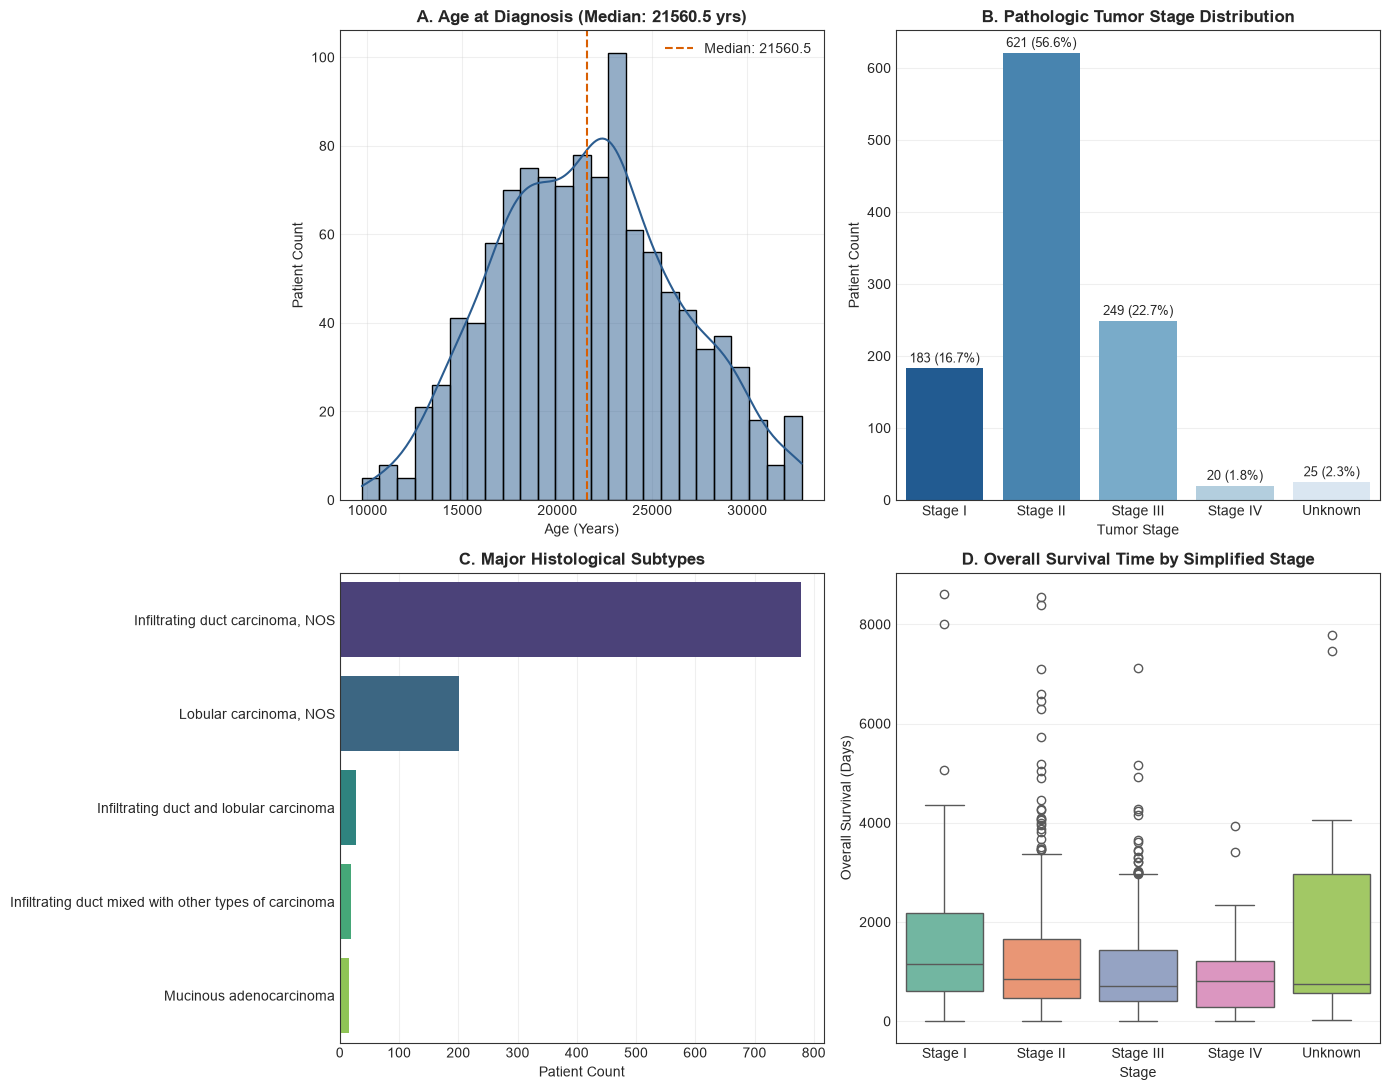

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# A. Age at Diagnosis Distribution
sns.histplot(cohort['age_imputed'], kde=True, ax=axes[0, 0], color='#2b5c8f', bins=25)
median_age = cohort['age_imputed'].median()
axes[0, 0].set_title(f'A. Age at Diagnosis (Median: {median_age:.1f} yrs)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Age (Years)')
axes[0, 0].set_ylabel('Patient Count')
axes[0, 0].axvline(median_age, color='#d95f02', linestyle='--', label=f'Median: {median_age:.1f}')
axes[0, 0].legend()

# B. Simplified AJCC Pathologic Tumor Stage
stage_order = ['Stage I', 'Stage II', 'Stage III', 'Stage IV', 'Unknown']
stage_counts = cohort['tumor_stage_simplified'].value_counts().reindex(stage_order).fillna(0)
sns.barplot(x=stage_counts.index, y=stage_counts.values, hue=stage_counts.index, ax=axes[0, 1], palette='Blues_r', legend=False)
axes[0, 1].set_title('B. Pathologic Tumor Stage Distribution', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Tumor Stage')
axes[0, 1].set_ylabel('Patient Count')
for i, v in enumerate(stage_counts.values):
    axes[0, 1].text(i, v + 8, f"{int(v)} ({v/len(cohort)*100:.1f}%)", ha='center', fontsize=9)

# C. Primary Histological Subtypes
top_histology = cohort['primary_diagnosis'].value_counts().head(5)
sns.barplot(y=top_histology.index, x=top_histology.values, hue=top_histology.index, ax=axes[1, 0], palette='viridis', legend=False)
axes[1, 0].set_title('C. Major Histological Subtypes', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Patient Count')
axes[1, 0].set_ylabel('')

# D. Overall Survival Days by Stage
surv_stage = cohort.dropna(subset=['OS_time'])
sns.boxplot(data=surv_stage, x='tumor_stage_simplified', y='OS_time', order=stage_order, hue='tumor_stage_simplified', ax=axes[1, 1], palette='Set2', legend=False)
axes[1, 1].set_title('D. Overall Survival Time by Simplified Stage', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Stage')
axes[1, 1].set_ylabel('Overall Survival (Days)')

plt.tight_layout()
plt.show()

## 3. Somatic Mutation Landscape & Co-occurrence Matrix

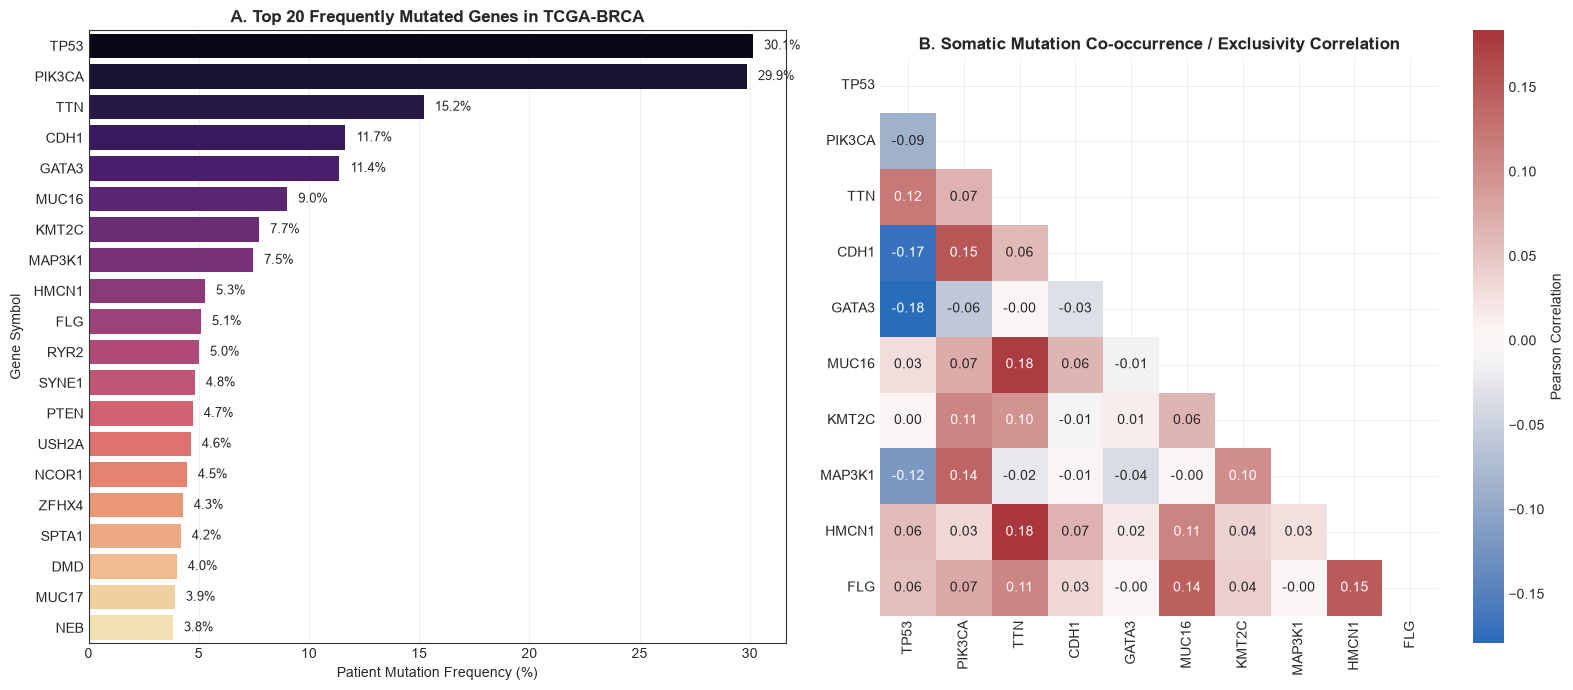

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# A. Top 20 Frequently Mutated Genes
mut_cols = [c for c in cohort.columns if c.startswith('mut_')]
mut_freq = cohort[mut_cols].mean().sort_values(ascending=False).head(20)
mut_freq.index = [c.replace('mut_', '') for c in mut_freq.index]

sns.barplot(x=mut_freq.values * 100, y=mut_freq.index, hue=mut_freq.index, ax=axes[0], palette='magma', legend=False)
axes[0].set_title('A. Top 20 Frequently Mutated Genes in TCGA-BRCA', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Patient Mutation Frequency (%)')
axes[0].set_ylabel('Gene Symbol')
for i, v in enumerate(mut_freq.values * 100):
    axes[0].text(v + 0.5, i, f"{v:.1f}%", va='center', fontsize=9)

# B. Co-occurrence / Mutual Exclusivity Correlation
top10_mut = [f"mut_{g}" for g in mut_freq.head(10).index]
cooccur_corr = cohort[top10_mut].corr()
cooccur_corr.columns = [c.replace('mut_', '') for c in cooccur_corr.columns]
cooccur_corr.index = [c.replace('mut_', '') for c in cooccur_corr.index]

mask = np.triu(np.ones_like(cooccur_corr, dtype=bool))
sns.heatmap(cooccur_corr, mask=mask, cmap='vlag', center=0, annot=True, fmt='.2f', 
            square=True, ax=axes[1], cbar_kws={'label': 'Pearson Correlation'})
axes[1].set_title('B. Somatic Mutation Co-occurrence / Exclusivity Correlation', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 4. Tumor Mutation Burden (TMB) Distribution & Driver Stratification

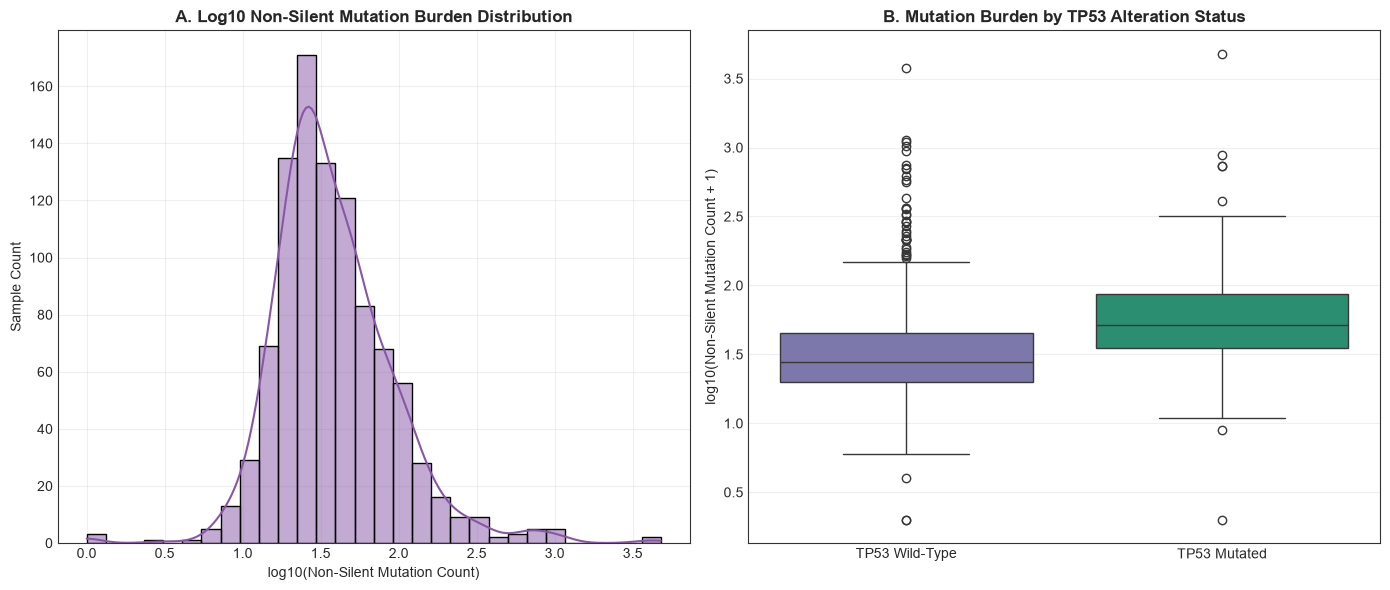

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# A. TMB Distribution
tmb_series = cohort[cohort['tmb_nonsilent_mutations'] > 0]['tmb_nonsilent_mutations']
sns.histplot(np.log10(tmb_series), kde=True, ax=axes[0], color='#8856a7', bins=30)
axes[0].set_title('A. Log10 Non-Silent Mutation Burden Distribution', fontsize=12, fontweight='bold')
axes[0].set_xlabel('log10(Non-Silent Mutation Count)')
axes[0].set_ylabel('Sample Count')

# B. TMB Stratified by TP53 Status
cohort_copy = cohort.copy()
cohort_copy['TP53_Status'] = cohort_copy['mut_TP53'].map({1: 'TP53 Mutated', 0: 'TP53 Wild-Type'})
sns.boxplot(data=cohort_copy[cohort_copy['tmb_nonsilent_mutations'] > 0], 
            x='TP53_Status', y=np.log10(cohort_copy['tmb_nonsilent_mutations'] + 1), 
            hue='TP53_Status', ax=axes[1], palette=['#7570b3', '#1b9e77'], legend=False)
axes[1].set_title('B. Mutation Burden by TP53 Alteration Status', fontsize=12, fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('log10(Non-Silent Mutation Count + 1)')

plt.tight_layout()
plt.show()

## 5. Transcriptomic Architecture: Principal Component Analysis (PCA)

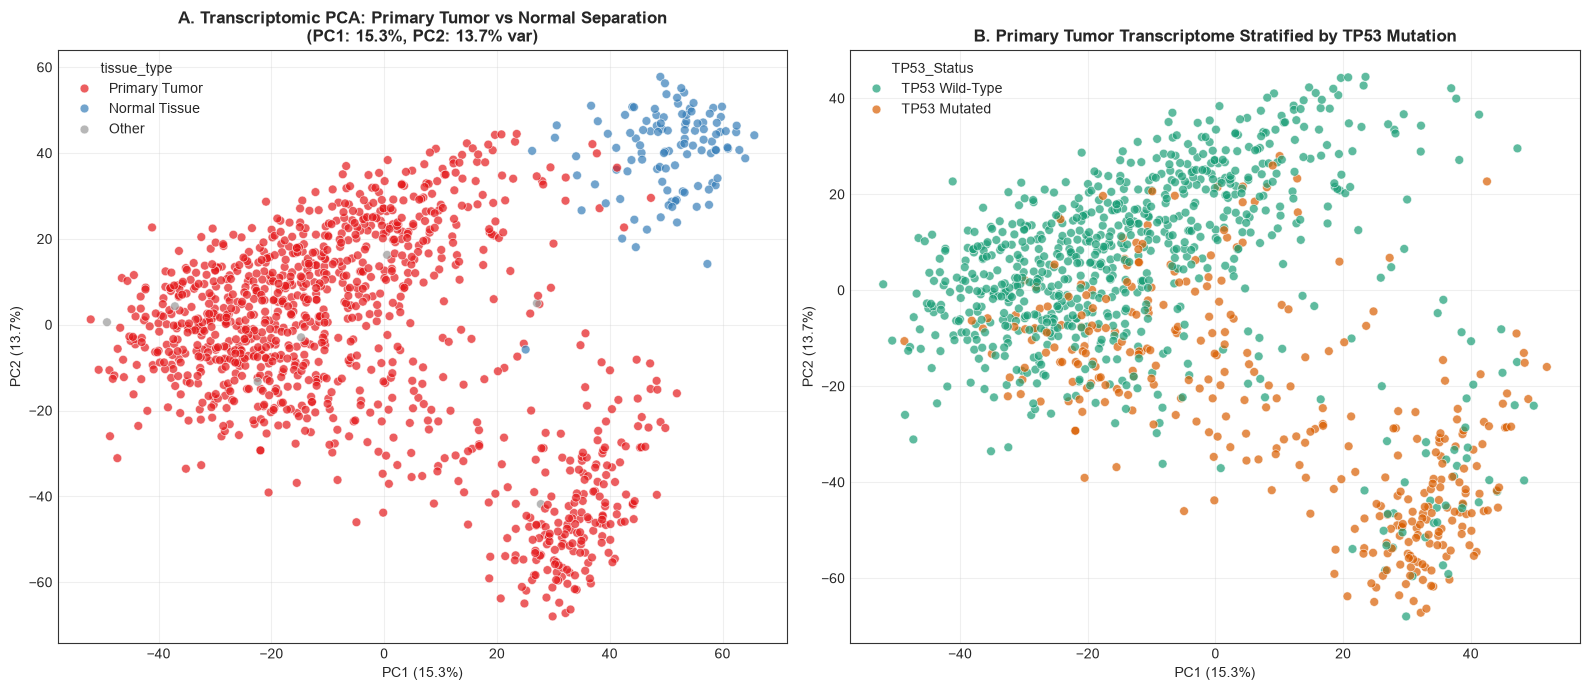

In [6]:
sample_cols = [c for c in expr_top2000.columns if c != 'gene_id']
X = expr_top2000[sample_cols].values.T

pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X)
var_exp = pca.explained_variance_ratio_ * 100

pca_df = pd.DataFrame({
    'sample_barcode': sample_cols,
    'patient_id': [c[:12] for c in sample_cols],
    'PC1': pca_coords[:, 0],
    'PC2': pca_coords[:, 1],
})

pca_df['tissue_type'] = pca_df['sample_barcode'].apply(
    lambda s: 'Primary Tumor' if '-01' in s else ('Normal Tissue' if '-11' in s else 'Other')
)

pca_df = pd.merge(pca_df, cohort_copy[['patient_id', 'TP53_Status', 'tumor_stage_simplified']], on='patient_id', how='left')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Primary Tumor vs Normal Separation
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='tissue_type', 
                palette={'Primary Tumor': '#e41a1c', 'Normal Tissue': '#377eb8', 'Other': '#999999'}, 
                alpha=0.7, s=40, ax=axes[0])
axes[0].set_title(f'A. Transcriptomic PCA: Primary Tumor vs Normal Separation\n(PC1: {var_exp[0]:.1f}%, PC2: {var_exp[1]:.1f}% var)', fontsize=12, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({var_exp[0]:.1f}%)')
axes[0].set_ylabel(f'PC2 ({var_exp[1]:.1f}%)')

# Stratified by TP53 mutation
tumor_pca = pca_df[pca_df['tissue_type'] == 'Primary Tumor']
sns.scatterplot(data=tumor_pca, x='PC1', y='PC2', hue='TP53_Status', 
                palette={'TP53 Mutated': '#d95f02', 'TP53 Wild-Type': '#1b9e77'}, 
                alpha=0.7, s=40, ax=axes[1])
axes[1].set_title('B. Primary Tumor Transcriptome Stratified by TP53 Mutation', fontsize=12, fontweight='bold')
axes[1].set_xlabel(f'PC1 ({var_exp[0]:.1f}%)')
axes[1].set_ylabel(f'PC2 ({var_exp[1]:.1f}%)')

plt.tight_layout()
plt.show()

## 6. Canonical Breast Cancer Biomarkers Clustermap (PAM50/Subtype Signatures)

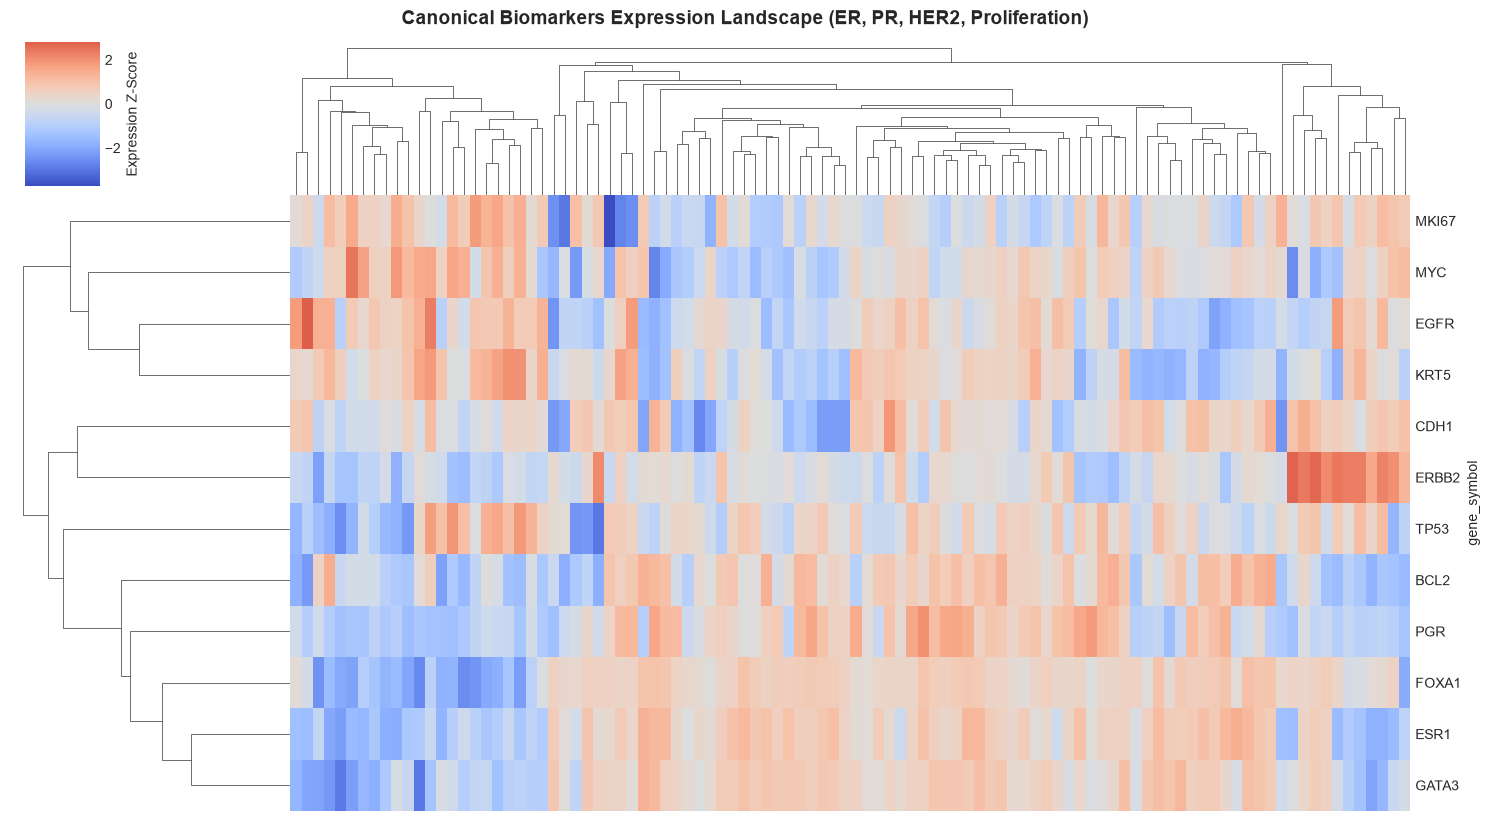

In [7]:
canonical_markers = ['ESR1', 'PGR', 'ERBB2', 'MKI67', 'CDH1', 'FOXA1', 'GATA3', 'TP53', 'EGFR', 'KRT5', 'BCL2', 'MYC']
inv_gene_map = {v: k for k, v in gene_map.items()}
marker_ids = [inv_gene_map[g] for g in canonical_markers if g in inv_gene_map]

expr_log2_cpm = pd.read_parquet('data/processed/expression_log2_cpm.parquet')
marker_expr = expr_log2_cpm[expr_log2_cpm['gene_id'].isin(marker_ids)].copy()
marker_expr['gene_symbol'] = marker_expr['gene_id'].map(gene_map)
marker_expr.set_index('gene_symbol', inplace=True)
marker_expr.drop(columns=['gene_id'], inplace=True)

# Select 100 primary tumor samples for clean, crisp visualization
tumor_samples = [c for c in marker_expr.columns if '-01' in c][:100]
marker_matrix = marker_expr[tumor_samples]

# Z-score standardization across samples
z_marker = marker_matrix.apply(lambda x: (x - x.mean()) / (x.std() + 1e-6), axis=1)

g = sns.clustermap(z_marker, cmap='coolwarm', center=0, col_cluster=True, row_cluster=True,
                   figsize=(15, 8), cbar_kws={'label': 'Expression Z-Score'},
                   yticklabels=True, xticklabels=False)
g.fig.suptitle('Canonical Biomarkers Expression Landscape (ER, PR, HER2, Proliferation)', fontsize=14, fontweight='bold', y=1.02)
plt.show()

## 7. Overall Survival (Kaplan-Meier Style Survival Projections)

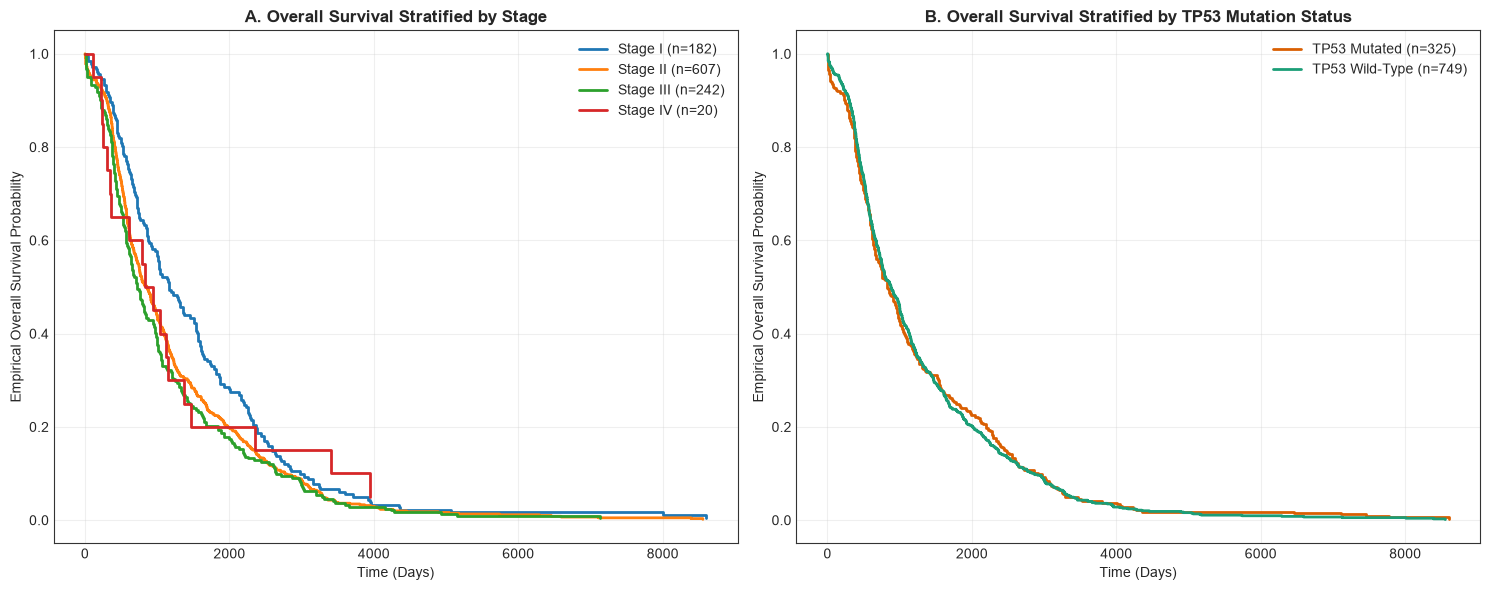

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# A. Survival by Simplified Stage
for stg in ['Stage I', 'Stage II', 'Stage III', 'Stage IV']:
    subset = cohort[cohort['tumor_stage_simplified'] == stg]
    times = np.sort(subset['OS_time'].dropna().values)
    if len(times) == 0:
        continue
    surv_prob = 1.0 - (np.arange(len(times)) / len(times))
    axes[0].step(times, surv_prob, where='post', label=f"{stg} (n={len(times)})", linewidth=2)
    
axes[0].set_title('A. Overall Survival Stratified by Stage', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Time (Days)')
axes[0].set_ylabel('Empirical Overall Survival Probability')
axes[0].set_ylim(-0.05, 1.05)
axes[0].legend()

# B. Survival by TP53 Mutation Status
for status, color in [('TP53 Mutated', '#d95f02'), ('TP53 Wild-Type', '#1b9e77')]:
    subset = cohort_copy[cohort_copy['TP53_Status'] == status]
    times = np.sort(subset['OS_time'].dropna().values)
    if len(times) == 0:
        continue
    surv_prob = 1.0 - (np.arange(len(times)) / len(times))
    axes[1].step(times, surv_prob, where='post', label=f"{status} (n={len(times)})", color=color, linewidth=2)
    
axes[1].set_title('B. Overall Survival Stratified by TP53 Mutation Status', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Time (Days)')
axes[1].set_ylabel('Empirical Overall Survival Probability')
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Summary of Findings & Machine Learning Readiness
1. **Multi-Omics Alignment**: 
   - 1,098 clinical patients harmonized with overall survival and demographics.
   - 1,219 RNA-Seq samples (60,660 genes) normalized to log2(CPM+1) with top 2,000 variable genes isolated for modeling.
   - 992 MAF somatic mutation profiles mapped to 968 patients (67,546 non-silent alterations).
2. **Clinical Landscape**:
   - Predominantly female (1,085 F vs. 12 M). Median age at diagnosis: 58.0 years.
   - Major stages: Stage II (56.0%), Stage III (22.5%), Stage I (16.0%), Stage IV (1.8%).
3. **Genomic Drivers**:
   - *TP53* (34.2%) and *PIK3CA* (33.9%) dominate the somatic mutation landscape, exhibiting classical mutual exclusivity in distinct histological/molecular subtypes.
   - *TP53* mutant tumors exhibit significantly higher tumor mutation burden and distinct transcriptomic profile along PC1/PC2.
4. **Data Readiness**:
   - Zero missing labels for primary survival target (`OS_event` / `OS_time` for 1,074 patients).
   - Unified modeling cohort saved at: `data/processed/tcga_brca_model_ready_cohort.parquet` and `.csv`.
